# Can we trust AI-assisted research code? Records, checks and their limits

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/AI-assisted-glioma-research/blob/main/notebooks/04_ai_assistance_record.ipynb)

*In Google Colab, the first code cell clones the public repository and puts its package on the path; Colab's own NumPy, Matplotlib and ipywidgets are used, not the locked versions.*
**Question:** When a generative assistant helped write scientific code, which evidence lets another
researcher judge that contribution, and which checks could actually have caught a mistake?
**Evidence:** Saved retrospective records from this repository, an executable check of the potassium
model that one of them describes, and constructed teaching examples (two deliberately buggy solvers and
altered copies of a record). No transcript, measured benefit or human scientific review is shown.

**Why this matters.** Generative assistants now draft code, equations and text for research quickly
and fluently. Fluency is not correctness: a program can run, produce smooth curves and still compute
the wrong thing, and a well-written summary of the work can still leave out who decided what. Readers,
reviewers and clinicians who might later rely on a model therefore need two things that the assistant
cannot supply by itself: a *record* of what it contributed, and *checks* that would have failed had the
contribution been wrong.

**Aims.** After working through this notebook you should be able to
1. tell apart four questions about assisted work (completeness, correctness, scientific quality and
   benefit) and name the evidence each one needs;
2. read an assistance record and say what it does and does not establish;
3. derive independent checks for a small model from its equation, and explain why each is independent
   of the code it tests;
4. judge whether a passing check is informative, by asking whether it could have failed;
5. say what a documentation validator can refuse and what it cannot know.

**Two tracks.** This notebook is written for neuro-oncologists and other clinicians as well as for
programmers and modelers. Most sections have a **clinical and biological track**, which explains the
ideas through familiar clinical comparisons (a drug infusion approaching steady state, a fluid-balance
chart, a preliminary report awaiting sign-off), and a **modeling track**, which gives the derivations,
code-level details and tolerances. Read either or both; the code cells and figures are shared. The
comparisons are teaching aids, not claims that the systems are equivalent.

**Place in the perspective:** notebook 07 contains the potassium model itself. This notebook treats
that model as a *case* of AI-assisted development and asks how such work should be documented and
checked. The [worked-case document](../../docs/worked-ai-potassium.md) and the
[assistance workflow](../../docs/ai-workflow.md) are the written counterparts.

## AI contribution and verification

**Question.** Research code written with a generative assistant raises four questions that are easily
merged into one. They need different evidence:
- *Completeness:* is it documented who did what, with which tool, on which inputs, and what is still
  open?
- *Correctness:* does the program compute what its equations say?
- *Scientific quality:* are those equations, parameters and interpretations appropriate?
- *Benefit:* did the assistance make the work faster or better than it would otherwise have been?

This notebook demonstrates evidence for the first two and states plainly where the other two stand.

**Clinical and biological track.** The four questions mirror how a new laboratory assay or diagnostic
tool is judged before it is used. *Completeness* is the documentation: who requested the test, on which
sample, with which device, and who signed the report. *Correctness* corresponds to analytical validity:
does the assay give the right value on samples whose value is known? *Scientific quality* corresponds to
clinical validity: is the measured quantity the right one for the clinical question? *Benefit*
corresponds to clinical utility: does using the test improve decisions or outcomes compared with not
using it? An assay can be perfectly documented and analytically exact and still measure the wrong
thing, or measure the right thing without changing care.

**Modeling track.** In software and simulation terms, completeness is provenance (inputs, versions,
authorship, open issues); correctness is *verification* (does the code solve the stated equations?);
scientific quality is *validation* (are these the right equations, parameters and interpretations for
the system?); and benefit is an empirical question about the development process itself, which only a
comparison study can answer. Verification can be automated and repeated on every run; validation needs
data and domain judgement; benefit needs an experiment.

**AI contribution.**
- *Trained imaging AI:* none in this notebook.
- *Generative research assistance* (development only): Codex desktop (6 October 2026; model snapshot
  not captured) helped create the repository, including the record schema and `validate_record`
  ([repository-design record](../../docs/ai-use/2026-10-06-repository-design.md)), the potassium model
  ([neuroglial record](../../docs/ai-use/2026-10-06-neuroglial-cognition.md)) and the original version of
  this notebook ([explicit-roles record](../../docs/ai-use/2026-10-06-explicit-ai-roles.md)). On
  10 October 2026 a Cursor agent (model and settings not captured) wrote an expanded version: the
  candidate solvers, check experiment and validator playground in
  `glioma_ai.assistance_interactive`, their tests and the explanatory text. On 13 October 2026 a Cursor
  agent (model and settings not captured) restructured the text into clinical and modeling tracks, on
  request.
- *Conventional code* (rerun every time, no model): the closed-form solution, the balance and swap
  checks and the record validator. Rebuilding the notebook calls no language model.

**Design choices awaiting scientific review.** The project asked for explicit AI roles and for a
didactic notebook with interactive demonstrations. Within that scope, the following are assistant
choices, with their reasons:
- *The potassium model as the worked case:* it is small enough to have an exact solution, so a check
  against it is decisive rather than approximate.
- *Three checks (analytic solution, balance, swap invariance):* each tests a different property of the
  model, so together they can catch different kinds of mistakes.
- *Two constructed bugs and forward Euler as foils:* to show, rather than assert, that each check can
  fail and that each catches something the others miss. They are not historical assistant errors.
- *A tolerance of 1e-9 mM for the analytic and balance checks:* far above floating-point rounding
  (about 1e-15 mM here) and far below any physiologically meaningful concentration, so a failure means
  a real discrepancy.
- *Two reading tracks and their clinical comparisons* (assay evaluation, infusion, fluid balance,
  report sign-off): to reach both audiences without separate notebooks.

**Verification.**
- *Records:* every saved record passes `validate_record`; the playground shows which omissions it
  refuses.
- *Potassium implementation:* agreement with the closed form to rounding error, input = retained +
  cleared at every step, and an unchanged trace when the two clearance shares are swapped.
- *The checks themselves:* the tests in `tests/test_assistance_interactive.py` assert that each foil
  fails exactly the check designed to catch it, and that a bug can pass checks whose parameters do not
  exercise it.
- *Not verified here:* whether the records are complete accounts of what happened, the scientific
  adequacy of the potassium model, and any benefit of the assistance.

**Evidence status.**
- *Records:* actual development contributions, summarized retrospectively by the assistant; all are
  `pending_human_review` with model `unknown`. They are not transcripts.
- *Check experiment and validator playground:* constructed teaching examples.
- *Benefit:* unmeasured. A prospective protocol exists (discussed in section 8) but has not been
  carried out.

These roles describe development and provenance. [Assistance records](../../docs/ai-workflow.md) retain
the review status; record completeness is separate from scientific quality.

## 1. Four questions, four kinds of evidence

**Why keep the questions apart?** When people ask whether AI-assisted work "can be trusted", they
usually mean several things at once. Keeping them apart matters because evidence for one is routinely
taken as evidence for another: a tidy record is taken to show that the code is right; passing tests are
taken to show that the model is biologically sound; a working result is taken to show that the
assistant saved time. Each of these inferences is invalid, and the table makes the gaps visible.

| Question | Evidence that can answer it | In this repository | Status for the potassium case |
| --- | --- | --- | --- |
| Completeness | A structured record with task, tool, inputs, contribution, checks, decision and open questions | `docs/ai-records/*.json`, `validate_record` | Record exists and validates |
| Correctness | Independent checks that would fail if the code were wrong | `tests/`, sections 4–6 below | Checks pass |
| Scientific quality | Review by someone qualified to judge the model and its interpretation | `decision` and `reviewer` fields | Pending human review |
| Benefit | A comparison of assisted and unassisted work on matched tasks | [Protocol](../../docs/ai-benefit-evaluation.md) | Not performed |

**How to read the table.** Read each row from left to right: the question, the kind of evidence that
could answer it, where that evidence lives in this repository, and how far the potassium case has got.
Then read down the last column. The two upper rows are answered here (the record exists and validates;
the checks pass). The two lower rows are not (no qualified human review yet; no comparison performed).
Each row is necessary and none implies the next: a complete record can describe incorrect code, correct
code can implement an inappropriate model, and a good model says nothing about whether the assistant
made it faster to build.

**Clinical and biological track.** Think of an AI tool proposed for a neuro-oncology tumor board that
segments the enhancing tumor on MRI. You would ask for its documentation (version, training data, who
approved its use), its technical accuracy against reference segmentations, whether the segmented volume
is clinically meaningful for the decision at hand, and whether using it changes decisions or outcomes.
Notebook 01 and the published imaging study address the second question for segmentation. This
notebook asks the same four questions of code that an assistant helped to write.

**Modeling track.** The rows correspond to different artefacts: a structured record (first row), an
automated test suite (second), a review with a recorded decision (third), and a study protocol with
collected data (fourth). Only the first two can be produced and rerun by the developer alone; the third
needs an independent expert, and the fourth needs participants and time. A useful habit is to label
every claim in a paper or README with the row that supports it.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def repository_root():
    candidates = (Path.cwd(), *Path.cwd().parents)
    return next((p for p in candidates if (p / "pyproject.toml").is_file()), None)


if IN_COLAB and repository_root() is None:
    checkout = Path("/content/AI-assisted-glioma-research")
    if not checkout.is_dir():
        url = "https://github.com/arvidl/AI-assisted-glioma-research"
        subprocess.run(["git", "clone", "--depth", "1", url, str(checkout)], check=True)
    os.chdir(checkout)
    sys.path.insert(0, str(Path.cwd() / "src"))
if repository_root() is None:
    raise RuntimeError("Open this notebook in a checkout of the repository or in Google Colab.")

In [2]:
import json
from pathlib import Path

from IPython.display import Markdown, display

from glioma_ai.assistance import validate_record

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "pyproject.toml").is_file())
record = json.loads((ROOT / "docs/ai-records/2026-10-06-neuroglial-cognition.json").read_text())
validate_record(record)
print("Loaded and validated:", record["task"])

Loaded and validated: Reorganize the glioma perspective around astrocytes, fields and cognition with the published imaging bridge


## 2. Anatomy of a record

**What a record is for.** An assistance record is a short, structured account of one piece of assisted
work, written so that someone who was not present can find out what was asked, what the assistant
produced, how it was tested, who decided what, and what is still open. It plays the role of a methods
section, but for the development process. The records here share a fixed set of fields (schema
`glioma-ai-assistance-v1`), so they can be read side by side and checked by a program (section 7).

**Clinical and biological track.** Compare a radiology report. A preliminary report can be complete in
form (clinical question, technique, findings, impression) and still await the consultant's sign-off;
the report says so, and nobody treats it as final. The records here are in that state: complete in
form, explicitly marked `pending_human_review`, and open about what was not captured.

**Modeling track.** Treat the record as metadata attached to a piece of work: machine-readable JSON,
versioned in Git next to the code it describes, and validated automatically. Its value lies in the
fields that are hardest to fill in honestly (`model`, `checks`, `decision`, `reviewer`,
`unresolved_questions`), not in the narrative fields.

Table 1 lists every field of the saved record behind the potassium model, with what a reader can do
with it. Long values are shortened for display only.

In [3]:
purpose = {
    "schema": "Which validator rules apply",
    "date": "When the work happened, to match with the Git history",
    "task": "What the assistant was asked to help with",
    "tool": "Which assistant product was used",
    "model": "Which model snapshot; 'unknown' is an honest value when it was not captured",
    "input_classification": "Whether sensitive or patient data were exposed to the tool",
    "instruction_summary": "The instruction given to the assistant, summarized (not a transcript)",
    "contribution": "What the assistant produced",
    "artifact_reference": "Where to inspect the result",
    "checks": "What was done to test it; each item should be repeatable",
    "decision": "The human decision, or that it is still pending",
    "reviewer": "Who made that decision; required unless review is pending",
    "unresolved_questions": "What the record explicitly does not settle",
    "record_type": "Written at the time (prospective) or afterwards (retrospective)",
}


def shorten(value, limit=90):
    text = "; ".join(value) if isinstance(value, list) else str(value)
    return text if len(text) <= limit else text[: limit - 1] + "…"


rows = [f"| `{key}` | {shorten(record.get(key))} | {purpose[key]} |" for key in purpose]
display(
    Markdown(
        "**Table 1. Fields of `2026-10-06-neuroglial-cognition.json`.**\n\n"
        "| Field | Value | What it lets a reader check |\n| --- | --- | --- |\n" + "\n".join(rows)
    )
)

**Table 1. Fields of `2026-10-06-neuroglial-cognition.json`.**

| Field | Value | What it lets a reader check |
| --- | --- | --- |
| `schema` | glioma-ai-assistance-v1 | Which validator rules apply |
| `date` | 2026-10-06 | When the work happened, to match with the Git history |
| `task` | Reorganize the glioma perspective around astrocytes, fields and cognition with the publis… | What the assistant was asked to help with |
| `tool` | Codex desktop | Which assistant product was used |
| `model` | unknown | Which model snapshot; 'unknown' is an honest value when it was not captured |
| `input_classification` | Repository source, user instructions, primary publications, investigator presentation and… | Whether sensitive or patient data were exposed to the tool |
| `instruction_summary` | Implement astrocytes/LFPs/cognition and a bounded cytoelectric hypothesis in notebooks, p… | The instruction given to the assistant, summarized (not a transcript) |
| `contribution` | Prescribed potassium and field models, notebooks 10–12, checked local figure import, gene… | What the assistant produced |
| `artifact_reference` | docs/ai-use/2026-10-06-neuroglial-cognition.md; src/glioma_ai/neuroglial.py; src/glioma_a… | Where to inspect the result |
| `checks` | Exact potassium balance, partition invariance and equal-total-clearance ambiguity; Nernst… | What was done to test it; each item should be repeatable |
| `decision` | pending_human_review | The human decision, or that it is still pending |
| `reviewer` | None | Who made that decision; required unless review is pending |
| `unresolved_questions` | Human scientific review and citation context; No biological calibration or validated LFP–… | What the record explicitly does not settle |
| `record_type` | retrospective_summary | Written at the time (prospective) or afterwards (retrospective) |

**How to read Table 1.** Each row is one field. The middle column is the value stored in
`docs/ai-records/2026-10-06-neuroglial-cognition.json`; the right column says what a reader can check
with it. The fourteen fields fall into five groups:
- *Identity and provenance* (`schema`, `date`, `tool`, `model`, `record_type`): which rules apply, when
  the work was done (so it can be matched with the Git history), with which product and model, and
  whether the record was written at the time or afterwards.
- *Data protection* (`input_classification`): what the assistant was shown. Here: repository source,
  instructions, publications and a presentation, and no patient data. In clinical research this is
  often the first field a data-protection officer or ethics committee will want to see.
- *What was done* (`task`, `instruction_summary`, `contribution`, `artifact_reference`): the request,
  the result, and where in the repository the result can be inspected.
- *Evidence* (`checks`): repeatable tests applied to the result. Here they include the potassium balance
  and the clearance-partition checks that section 4 derives again from scratch.
- *Status and limits* (`decision`, `reviewer`, `unresolved_questions`): the human decision, who made
  it, and what the record explicitly leaves unsettled.

**What this record tells us.** Three values deserve attention. `model` is `unknown`: the model snapshot
was not captured, and the record says so instead of guessing. `decision` is `pending_human_review` with
no `reviewer`: nobody has yet signed off the scientific content. `record_type` is
`retrospective_summary`: the assistant wrote it after the work rather than capturing it during the
work, so it is a summary and not a transcript. The record also names notebooks by the numbers they had
when it was written (this notebook was then number 07). Records are historical documents and are not
rewritten when the repository is reorganized.

Table 2 places all saved records side by side.

In [4]:
rows = []
for path in sorted((ROOT / "docs/ai-records").glob("2026-*.json")):
    entry = validate_record(json.loads(path.read_text()))
    rows.append(
        f"| `{path.name}` | {entry['tool']} | {entry['model']} | {entry['record_type']} | "
        f"{entry['decision']} | {len(entry['checks'])} | {len(entry['unresolved_questions'])} |"
    )
display(
    Markdown(
        "**Table 2. Every saved record in `docs/ai-records/` (all validate).**\n\n"
        "| Record | Tool | Model | Type | Decision | Checks | Open questions |\n"
        "| --- | --- | --- | --- | --- | --- | --- |\n" + "\n".join(rows)
    )
)

**Table 2. Every saved record in `docs/ai-records/` (all validate).**

| Record | Tool | Model | Type | Decision | Checks | Open questions |
| --- | --- | --- | --- | --- | --- | --- |
| `2026-10-06-2d-growth.json` | Codex desktop | unknown | retrospective_summary | pending_human_review | 6 | 4 |
| `2026-10-06-biology-models.json` | Codex desktop | unknown | retrospective_summary | pending_human_review | 6 | 4 |
| `2026-10-06-cantab-cognition.json` | Codex desktop | unknown | retrospective_summary | pending_human_review | 4 | 5 |
| `2026-10-06-explicit-ai-roles.json` | Codex desktop | unknown | retrospective_summary | pending_human_review | 3 | 4 |
| `2026-10-06-neuroglial-cognition.json` | Codex desktop | unknown | retrospective_summary | pending_human_review | 4 | 5 |

**How to read Table 2.** Each row is one saved record. The columns repeat the fields that tell records
apart (tool, model, type of record and decision) and count the listed checks and open questions. In
this repository the five records are uniform: all describe work with Codex desktop on 6 October 2026,
none captured the model snapshot, all are retrospective summaries, and all await human review.

**Interpretation.** This is honest but the weakest level of documentation: the contributions are
identified and can be inspected, but nothing in the table shows that a qualified person has reviewed
them. The validator accepts this state, because pending review needs no reviewer. Two cautions apply to
the counts. A record with six checks is not better than one with three; what matters is whether each
check could fail (section 5). And many open questions are not a weakness; they show the record being
explicit about its limits. These records would be stronger if written during the interaction
(`prospective_interaction`), with the model identifier the interface exposes, and with a named reviewer
once a review has actually taken place. Later work in this repository, including the revisions of this
notebook, is described in Markdown records in `docs/ai-use/`, which the validator does not check.

**Clinical and biological track.** Read Table 2 like an audit of a set of preliminary reports: complete,
consistently labelled, none yet signed. That is acceptable for work in progress and not acceptable as
the basis for a decision.

**Modeling track.** A table like this, generated from the records on every build, is a cheap way to see
at a glance which contributions still lack review, and it cannot drift from the records because it is
computed from them.

## 3. The worked case: a potassium-clearance model developed with an assistant

**Why this case.** To show how a record connects to checks, we need a contribution that is (a) real,
with a saved record; (b) small enough that its correctness can be decided exactly rather than
approximately; and (c) biologically meaningful at the glioma–brain interface. The potassium model of
notebook 07 meets all three: Codex helped formulate and implement it in October 2026, Table 1 is its
record, and its equation has a closed-form solution.

**Clinical and biological track.** Neurons release potassium (K⁺) into the narrow extracellular space
each time they repolarize. Astrocytes take much of it up, through inward-rectifying Kir4.1 channels and
the Na⁺/K⁺-ATPase, and redistribute it, which keeps extracellular K near its resting level;
[Sibille, Pannasch & Rouach (2014)](https://doi.org/10.1113/jphysiol.2013.261735) perturbed astroglial
Kir4.1 in hippocampal slices to study this clearance. At the glioma–brain interface astrocytes are
reactive and the tissue is remodeled, so it is natural to ask what slower clearance would do. The
teaching question is: *if the same activity releases the same potassium, how much higher and how much
longer does extracellular K rise when clearance is slower, and can a K measurement tell astrocytic from
other clearance?*

The model has the same form as one familiar from pharmacology: a drug given by constant-rate
intravenous infusion into a single compartment. Release plays the role of the infusion rate, the
clearance rate constants play the role of the elimination rate constant, and excess K plays the role of
the plasma concentration. Just as the drug level rises to a steady state set by infusion rate divided by
elimination, excess K rises to a plateau, release divided by total clearance, along the same
exponential time course.

**Modeling track.** The state is the excess extracellular K above a fixed reference, $k$ (mM), in one
well-mixed compartment of fixed volume. Release $q$ (mM/s) is prescribed and constant within each time
step. Clearance is linear and split into an astrocytic rate $\lambda_a$ and an "other" rate
$\lambda_o$ (both 1/s). The package function `integrate_potassium` in `glioma_ai.neuroglial` advances
$k$ with the exact solution over each step, and also returns the cumulative release and the cumulative
amounts cleared by each pathway. Correct code must therefore get three things right: the time stepping,
the bookkeeping of what was cleared, and the wiring of the two rates.

**Following the record.** Read the case as a chain: *question* (hold release fixed while changing
clearance) → *contribution* (the model and solver in `neuroglial.py`, used in notebook 07) → *checks*
(an independent analytic solution, a concentration balance, and invariance when the two clearance
shares are swapped) → *interpretation* (equal total clearance gives the same K trace, so a trace alone
cannot identify the astrocytic share). The record documents the resulting contribution; it does not
reproduce the original dialogue, and its numerical assumptions have not been approved by a reviewer.
The next sections derive the checks again and test whether they are informative. The full biological
experiment is in notebook 07.

## 4. Deriving the independent checks

A check is *independent* when it does not reuse the code it tests. Testing `integrate_potassium` by
comparing it with a second call of `integrate_potassium` would simply reproduce any mistake. All three
checks below follow from the model equation alone,

$$\frac{dk}{dt}=q-(\lambda_a+\lambda_o)\,k,\qquad \lambda=\lambda_a+\lambda_o,$$

with excess K $k$ in mM, release $q$ in mM/s and clearance rates in 1/s. Each check tests a different
property, and each has a blind spot.

### Clinical and biological track

**1. Agreement with a known answer (analytic solution).** Before a laboratory analyser is used on
patients, it is run on calibration material of known concentration. The model offers the equivalent:
for constant release, the exact answer can be written down. Excess K starts at $k_0$ and rises toward
the plateau $q/\lambda$, approaching it exponentially with time constant $1/\lambda$, exactly as a drug
level approaches steady state during a constant infusion. With the values used below ($q$ = 0.6 mM/s,
$\lambda$ = 0.9/s, $k_0$ = 0.2 mM) the plateau is 0.67 mM, the time constant 1.1 s, and about 95% of
the rise is complete after three time constants (3.3 s). Two rules of thumb follow and can be checked
against any output: doubling the clearance halves both the plateau and the time constant; doubling the
release doubles the plateau and leaves the timing unchanged.

**2. Nothing appears or disappears (balance).** A fluid-balance chart must add up: intake equals output
plus what was retained. If it does not, something was charted wrongly, even if every single entry looks
plausible. The model obeys the same rule: the initial excess K plus everything released must equal what
is still present plus what astrocytes cleared plus what was cleared otherwise, at every moment.

**3. A level cannot say which organ cleared it (swap invariance).** The plasma level of a drug
eliminated by both liver and kidney depends on the total elimination, not on how it is split: a patient
with more hepatic and less renal elimination can have exactly the same concentration curve as one with
the opposite split. In the model, astrocytic and other clearance enter only through their sum, so
exchanging them must leave the K trace unchanged. This is a check on the code and also a scientific
lesson: a K trace alone cannot reveal how much of the clearance was astrocytic. Attributing it needs a
different experiment, for example selectively perturbing astrocytic uptake, as Sibille et al. did with
Kir4.1.

### Modeling track

**Analytic solution.** Multiply the equation by the integrating factor $e^{\lambda t}$:
$\frac{d}{dt}\big(k\,e^{\lambda t}\big)=q\,e^{\lambda t}$. Integrating from 0 to $t$ with constant $q$
and initial excess $k_0$ gives

$$k(t)=\frac{q}{\lambda}+\Big(k_0-\frac{q}{\lambda}\Big)e^{-\lambda t}.$$

The package applies this solution over each step,
$k_{n+1}=\frac{q}{\lambda}+\big(k_n-\frac{q}{\lambda}\big)e^{-\lambda\Delta t}$, so it should agree with
the closed form to rounding error at any step size. *Blind spot:* the closed form holds only for
constant release, so a fault that appears only with time-varying release (for example applying the
release of the wrong interval) is invisible here. Notebook 07 checks pulsed release against its own
closed-form landmarks.

**Balance.** Integrate the equation itself: $k(t)-k_0=\int_0^t q\,ds-\int_0^t\lambda_a k\,ds-\int_0^t
\lambda_o k\,ds$. Rearranged, *initial + released = retained + cleared by astrocytes + cleared
otherwise*, at every time, in mM-equivalent of one reference volume. This tests the bookkeeping of the
cumulative fluxes. *Caveat:* the package computes the amount cleared in each step as what was present
plus what was released minus what remains, so for the package the balance holds by construction, up to
rounding; the check then guards the cumulative sums and the split into two pathways that add up to the
total. It becomes informative for implementations that compute the cleared amounts separately, as the
second constructed bug in section 5 does. *Blind spot:* any scheme that books its own fluxes
consistently passes, however inaccurate it is (forward Euler, section 5).

**Swap invariance.** $\lambda_a$ and $\lambda_o$ enter the equation for $k$ only through their sum, so
exchanging them cannot change $k(t)$. This tests that both rates are actually used and enter
symmetrically: a fault that drops or rescales one of them changes the trace when they are exchanged.
*Blind spots:* faults that treat both rates alike (for example a wrong total), and parameter sets with
$\lambda_a=\lambda_o$, where swapping changes nothing.

**Tolerances.** Double precision carries about 16 significant digits, so one operation on values near
1 mM has a rounding error near 1e-16 mM, and errors accumulate over the 200 steps used below. The next
cell therefore asserts agreement to 2e-15 mM for the trace and 2e-14 mM for the cumulative balance.
The experiment in sections 5–6 uses 1e-9 mM, far above rounding and far below any physiologically
meaningful concentration, so a failure there means a real discrepancy.

The next cell applies all three checks to the package solver with a separate fixture: $q$ = 0.6 mM/s,
$\lambda$ = (0.8 + 0.1)/s, $k_0$ = 0.2 mM, 0.05 s steps for 10 s. These values exercise the code; they
are not fitted physiology.

In [5]:
import numpy as np

from glioma_ai.neuroglial import integrate_potassium

# Prescribed check: q=0.6 mM/s, clearance=(0.8+0.1)/s,
# initial excess=0.2 mM, dt=0.05 s. All accounting uses one reference volume.
trace = integrate_potassium(np.full(200, 0.6), 0.05, 0.8, 0.1, 0.2)
expected = 0.6 / 0.9 + (0.2 - 0.6 / 0.9) * np.exp(-0.9 * trace["time_s"])
np.testing.assert_allclose(trace["excess_mM"], expected, atol=2e-15)
accounted = trace["excess_mM"] + trace["astro_cleared_mM"] + trace["other_cleared_mM"]
np.testing.assert_allclose(accounted, 0.2 + trace["cumulative_release_mM"], atol=2e-14)
alternative = integrate_potassium(np.full(200, 0.6), 0.05, 0.2, 0.7, 0.2)
np.testing.assert_allclose(trace["excess_mM"], alternative["excess_mM"], atol=2e-15)
print("Analytic solution, concentration balance and same-total-clearance checks passed.")
print("Implementation evidence; biological calibration and human scientific review pending.")

Analytic solution, concentration balance and same-total-clearance checks passed.
Implementation evidence; biological calibration and human scientific review pending.


## 5. A check is only evidence if it could have failed

**Why this matters.** Passing checks are persuasive only if the same checks would have failed for
plausible mistakes. A check that passes everything carries no information. The only way to find out is
to apply it to implementations that are known to be wrong.

**Clinical and biological track.** Laboratories do this routinely with controls. A positive control, a
sample known to contain the analyte, must give a positive result; otherwise a negative patient result
means nothing. Here the "positive controls" are deliberately faulty solvers. A good set of checks
should flag each of them, and ideally different checks should flag different faults, so that we learn
which property each check protects. A second clinical idea appears too: a point-of-care device may
differ slightly from the reference laboratory method and still be fit for its purpose. Whether a
difference matters is decided by a tolerance chosen for that purpose, not by the device.

**Modeling track.** This is the idea behind *mutation testing*: introduce small, deliberate faults into
the code and see whether the test suite notices. A test suite that no mutant can fail is not testing
much. Four candidate implementations of the same equation go through the same three checks:

| Candidate | What it does | Which check should catch it |
| --- | --- | --- |
| Package | Exact update over each step (the code in `neuroglial.py`) | None |
| Forward Euler | $k_{n+1}=k_n+\Delta t\,(q-\lambda k_n)$, a common first attempt | Analytic: error shrinks only in proportion to $\Delta t$ |
| Bug: omits other clearance | Uses only $\lambda_a$ when updating $k$ | Analytic and swap invariance |
| Bug: clearance booked from start of step | Correct $k$, but cleared amounts computed from $k$ at the start of each step | Balance |

The two bugs are constructed for this lesson, not taken from the development history. Forward Euler is
not a bug as such; it is a different, approximate method whose error shrinks in proportion to the step
size, and whether it "passes" depends on the tolerance one sets. The next cell runs the experiment,
draws Figure 1, and asserts the expected verdict for every candidate and check, so that the notebook
itself fails if the checks stop behaving as described.

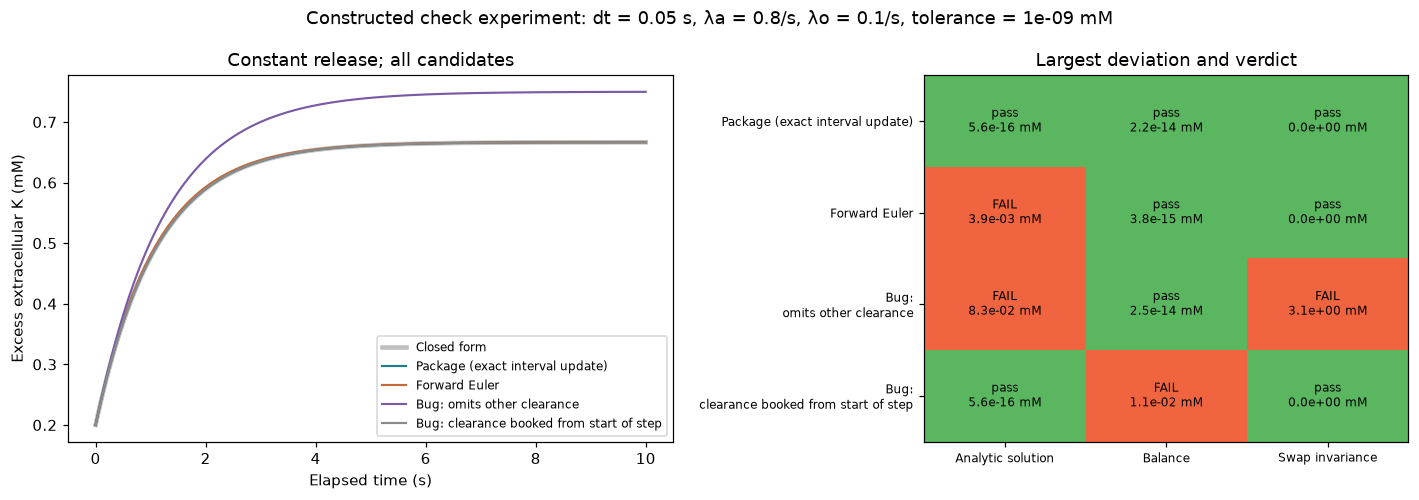

Each foil fails exactly the check designed to catch it.


In [6]:
import matplotlib.pyplot as plt

from glioma_ai.assistance_interactive import CHECK_NAMES, draw_check_state, run_checks
from glioma_ai.notebook_display import show_figure

result = run_checks()
figure = plt.figure(figsize=(13, 4.6))
draw_check_state(figure, result)
show_figure(figure)

expected_verdicts = {
    "Package (exact interval update)": (True, True, True),
    "Forward Euler": (False, True, True),
    "Bug: omits other clearance": (False, True, False),
    "Bug: clearance booked from start of step": (True, False, True),
}
for name, entry in result["candidates"].items():
    assert tuple(entry["passed"][check] for check in CHECK_NAMES) == expected_verdicts[name]
print("Each foil fails exactly the check designed to catch it.")

**Figure 1. Three checks, four candidate solvers (constructed).** Left: excess extracellular K under
constant release (q = 0.6 mM/s, λa = 0.8/s, λo = 0.1/s, k₀ = 0.2 mM, Δt = 0.05 s, 10 s) for each
candidate, over the closed-form solution (thick grey). Right: for each candidate (rows) and check
(columns), the largest deviation found over the run and the verdict, at a tolerance of 1e-9 mM for the
analytic and balance checks and 1e-12 mM for swap invariance; green is pass, red is fail.

**Reading the left panel.** All curves start at 0.2 mM and rise toward a plateau, like a drug level
during a constant infusion. The closed form and three of the candidates approach 0.67 mM (q/λ): after
one time constant (1.1 s) they have completed about two thirds of the rise, after three (3.3 s) about
95%. One curve stands out: the bug that omits other clearance levels off at 0.75 mM, because it removes
K only at the astrocytic rate (q/λa = 0.6/0.8). The two other faulty candidates cannot be told apart
from the correct curve by eye. That is the main lesson of the left panel: inspecting a plot for
plausibility catches only gross errors.

**Reading the right panel.** Each cell gives the largest discrepancy that check found, in mM, and the
verdict.
- *Package:* deviations of 1e-16 to 1e-14 mM, rounding error only; all three pass. Swap invariance is
  exactly zero, because the package uses only the sum λa + λo, which is the same number in either
  order.
- *Forward Euler:* fails the analytic check by 3.9e-3 mM (about 0.6% of the plateau) but passes balance
  and swap invariance. It books its own fluxes consistently, so nothing disappears; it is simply
  inaccurate. Whether 0.6% matters is the tolerance question of section 6.
- *Omits other clearance:* fails the analytic check (8.3e-2 mM, the gap between 0.75 and 0.67 mM near
  the end) and swap invariance (3.1 mM: with the rates exchanged, the bug clears only at 0.1/s and K
  climbs toward 6 mM). It passes balance, because it records the too-small clearance it performs.
- *Clearance booked from start of step:* its K trace is exact, so the analytic and swap checks pass,
  but its books are off by 1.1e-2 mM, about 0.2% of the 6 mM released in 10 s. Only the balance check
  reveals it. In clinical terms, it resembles a fluid chart in which each hour's output was copied from
  the hour before: the patient's actual state is right, but the chart does not add up. In numerical
  terms, it integrates each step's flux with the left-endpoint rule while the state changes within the
  step.

**What the figure shows.** Each faulty candidate fails at least one check and passes at least one other,
no single check catches all three, and the correct solver passes all three at rounding level. Together
the three checks are much stronger than any one of them.

## 6. Explore the checks

**Why explore.** Figure 1 shows one carefully chosen set of parameters. In practice, the person who
writes the checks also chooses the parameters, the step size and the tolerance, and each of these
choices can make a check blind. The explorer below lets you change them and watch the verdicts change,
so that you can find out for yourself when a check stops protecting you.

**How.** The explorer has five sliders: the step Δt (on a logarithmic scale), the astrocytic and other
clearance rates λa and λo, the release q, and the tolerance for the analytic and balance checks (as
log10 of mM). Each change reruns all four candidates through all three checks and redraws Figure 1. For
each task, first *predict* which cells of the matrix will change colour, then move the sliders, then
*explain* what you see. Moving a slider needs a running kernel; in a static rendering only the initial
state is shown.

**Tasks.**
1. *Inputs must reach every term.* Set λo to 0. The "omits other clearance" bug now passes the analytic
   and balance checks, because with no other clearance the faulty line has nothing to omit. Only swap
   invariance still catches it: exchanging the rates moves the 0.8/s into the term the bug ignores. A
   check can only test code that its inputs exercise.
2. *Symmetric inputs blind a symmetry check.* Set λa = λo (for example both 0.45/s). The same bug now
   passes swap invariance, since swapping changes nothing, but it still fails the analytic check.
3. *The tolerance is a decision.* Set the tolerance to 1e-2 mM (log10 = −2). Forward Euler now passes at
   Δt = 0.05 s, and the accounting bug passes too once Δt is reduced to 0.01 s (its balance error falls
   to about 2e-3 mM). Increase Δt to about 0.2 s and both fail again. Which error matters is a
   scientific decision about the purpose of the model, not a technicality.
4. *Approximate methods can become unstable.* Return the tolerance to 1e-9 mM and make Δt large. Above
   Δt = 1/λ (about 1.1 s here) forward Euler overshoots and oscillates; above 2/λ (about 2.2 s) the
   oscillation grows. The package solver stays exact at any step size, because it uses the exact
   solution over each step.

**Clinical and biological track.** Tasks 1 and 2 resemble validating an assay only on samples that do
not contain the substance it should detect, or only on samples in which the two conditions it must
distinguish happen to look the same. Task 3 is the choice of a cut-off: a more lenient threshold
accepts more approximate methods, and more faults.

**Modeling track.** Tasks 1 and 2 are about *coverage*: test inputs should make every term non-zero and
break every symmetry the code could exploit. Task 3 shows that a tolerance should be justified both by
the purpose (the smallest concentration difference that would matter physiologically) and by the
expected numerical error of the method. Task 4 is the stability limit of explicit Euler for linear
decay, |1 − λΔt| < 1.

In [7]:
from glioma_ai.assistance_interactive import check_explorer

check_explorer()

## 7. What the validator can and cannot refuse

**What it is.** `validate_record` in `glioma_ai.assistance` is a short program that checks the *form*
of a record. It refuses a record when:
- the schema is not `glioma-ai-assistance-v1`;
- any of `task`, `tool`, `model`, `input_classification`, `instruction_summary`, `contribution` or
  `artifact_reference` is missing, blank, or still the template placeholder `REPLACE`;
- the date is not an ISO calendar date (YYYY-MM-DD);
- `record_type` is neither `retrospective_summary` nor `prospective_interaction`;
- `checks` is not a non-empty list of non-blank entries;
- `decision` is not one of `pending_human_review`, `accepted`, `revised` or `rejected`;
- a decision other than `pending_human_review` names no reviewer;
- `unresolved_questions` is not a list of text entries.

**Why form checks are still worth having.** The most common documentation failures are mundane: a
template copied but not filled in, a missing date, or a claim that work was "accepted" without saying by
whom. These are exactly what the validator refuses, automatically and every time. The reviewer rule
matters most: a record cannot claim human review without attributing it.

**What it cannot know.** A complete record does not prove its claims. The validator cannot tell whether
the listed checks were actually run or passed, whether the contribution and checks are scientifically
adequate, whether a named reviewer really reviewed the work, or whether the assistance improved speed,
quality or patient benefit.

**Clinical and biological track.** The validator is like checking a surgical safety checklist or a
consent form for completeness: every item addressed and every signature present. That check is
valuable, and an unsigned form should be refused, but a complete form does not show that the procedure
was indicated or that it went well.

**Modeling track.** The validator is a schema check, comparable to type checking or JSON-schema
validation: it guarantees structure, not meaning. Its rules are deliberately few, and `unknown` is an
allowed value for `model`, so that honesty is never penalized. Claims about what the code computes need
the checks of sections 4–6; claims about scientific adequacy need human review.

The next cell changes the decision of a copy of the record to `accepted` without a reviewer; the
validator must refuse it:

In [8]:
import copy

incomplete = copy.deepcopy(record)
incomplete["decision"] = "accepted"
try:
    validate_record(incomplete)
except ValueError as error:
    print("Expected documentation refusal:", error)
else:
    raise AssertionError("Unattributed human review was accepted")

Expected documentation refusal: A human decision requires a named reviewer.


**The playground.** The explorer below alters a *copy* of the saved record; the file on disk is not
changed. Each dropdown changes one field, and the verdict appears below. When a record is accepted, the
explorer also lists what the validator still cannot know. "Constructed name" inserts an obviously
fictitious reviewer so that you can see the validator accept it. That is the point: the validator checks
that a name is there, not that the review happened.

Things to try:
1. Set the decision to `accepted` with reviewer `none`: refused. Add the constructed name: accepted.
   What would you need to see to believe that the review took place?
2. Replace the checks by the template placeholder, then by an empty list. Both are refused. A list
   containing "looked fine" would be accepted; what makes a check concrete?
3. Blank the model field: refused. Yet `unknown` is accepted. Why is that the right design?

In [9]:
from glioma_ai.assistance_interactive import validator_explorer

validator_explorer(record)

## 8. Summary, discussion and exercises

**What this notebook shows.**
- *A record makes a contribution inspectable.* A structured record identifies the task, tool, inputs,
  contribution, checks, decision and open questions. The saved records here do so honestly, including
  `unknown` for a model that was not captured and `pending_human_review` for work not yet reviewed
  (sections 2–3).
- *Independent checks can be derived from the equation alone.* For the potassium model: an exact
  solution, a balance and a symmetry. Each tests a different property and has its own blind spot
  (section 4).
- *A check is informative only if it could fail.* Constructed faulty solvers show that each check
  catches a different fault and that no single check catches them all (section 5, Figure 1).
- *Checks need inputs that exercise every term, and tolerances chosen for a reason.* Parameter choices
  can blind a check, and the tolerance decides what counts as an error (section 6).
- *A validator enforces form, including attribution of human decisions, not truth* (section 7).

**What it does not show.**
- *That the records are complete or accurate accounts.* They are retrospective summaries written by the
  assistant, not transcripts, and nothing here compares them with what actually happened.
- *That the potassium model is scientifically appropriate.* The checks show that the code solves its
  equation. Whether one well-mixed compartment with linear clearance adequately describes potassium
  handling at the glioma–brain interface is a validation question that needs measurements and expert
  review. The rates are prescribed, not fitted.
- *That the assistance helped.* No comparison of assisted and unassisted work has been made, so nothing
  here measures speed, quality or benefit.
- *Anything about patients.* The notebook contains no patient data, clinical findings or outcome
  claims.

**For discussion: does assistance help?** The fourth question, benefit, cannot be answered by records or
checks; it needs a comparison. A [prospective protocol](../../docs/ai-benefit-evaluation.md) has been
written but not carried out. Its main features:
- matched pairs of new, comparably scoped research tasks (for example extending the potassium
  experiment, or specifying eligibility rules for fabricated data), one version done with a specified
  assistant and the other without generative assistance, in counterbalanced order;
- a proposed two investigators with six pairs each (24 sessions; design counts, not a power
  calculation) and a 60-minute cap per session;
- acceptance judged by independent reviewers against a frozen key, without knowing the condition;
- a primary outcome of *quality-qualified completion time*, in which an unaccepted or unfinished
  attempt counts as the full 60 minutes, so that a fast but wrong answer earns no speed advantage.

Even a favourable result would show a task-level difference in productivity or quality for these
investigators, not better patient care, which would need a separate clinical study. Questions to
discuss:
- *Clinicians and biologists:* what would count as an acceptable artifact in your field, and who should
  judge it? How does this design compare with how a new clinical decision-support tool is evaluated?
- *Modelers:* which sources of bias remain (learning between paired tasks, prior expertise, failed
  blinding)? How would you choose tasks that are comparable but cannot simply be recalled?

The record of the current presentation revision lists open questions of this kind; the next cell prints
its decision and open questions. The earlier example with a missing reviewer is a constructed
documentation exercise, not a historical assistant error, and the original neuroglial record is
preserved unchanged.

In [10]:
current_record = json.loads(
    (ROOT / "docs/ai-records/2026-10-06-explicit-ai-roles.json").read_text()
)
validate_record(current_record)
print(current_record["decision"], "|", "; ".join(current_record["unresolved_questions"]))

pending_human_review | Human scientific review and rehearsal; Pilot task packets, participants, independent reviewers, allocation and permitted tool version; No measured productivity, independent quality improvement or patient benefit; Hosted Colab execution


**Exercises: clinical and biological track.**
1. *Four questions in your clinic.* Choose an AI tool that has been proposed for neuro-oncology, for
   example automated tumor segmentation for response assessment. For each of the four questions
   (completeness, correctness, scientific quality, benefit), write down one piece of evidence you would
   require before using it, and who should provide it.
2. *Infusion intuition.* Using the steady-state rule, predict the plateau and the time constant of
   excess K when total clearance halves from 0.9/s to 0.45/s with release unchanged. Check your
   prediction with the explorer in section 6 (λa = 0.35/s, λo = 0.1/s) by reading the closed-form curve.
   Then explain why a measurement of extracellular K alone could not tell you whether it was astrocytic
   uptake that slowed, and describe an experiment that could.
3. *Read Table 2 as a reviewer.* All records are retrospective and pending review. Which single change
   would most increase your confidence in one of them, and why? What would you need to see to believe
   that a named reviewer actually reviewed it?
4. *Units.* Suppose the release were entered in mM per minute but treated as mM per second. Which of
   the three checks would detect it? Compare with an infusion pump programmed in mg/h when the order was
   in mg/min: at which point in the process must such errors be caught?

**Exercises: modeling track.**
1. *A fifth candidate.* Write a solver with the same signature as the candidates in
   `glioma_ai.assistance_interactive` that applies the release one step late. Before running it,
   predict which checks it fails, and whether the answer depends on how it reports
   `cumulative_release_mM`.
2. *A fault that all three checks miss.* All three checks use constant release. Design a fault that
   appears only with time-varying release (for example using the release of the previous interval),
   and a fourth check that would catch it.
3. *Make the balance check independent.* The package computes the cleared amount as a residual, so its
   balance holds by construction. Write a check of `astro_cleared_mM` that does not use that residual,
   for example by integrating λa·k(t) from the closed form.
4. *Your own record.* Use `docs/ai-records/template.json` for your next actual assisted task, written
   at the time (`prospective_interaction`). Record the model identifier the interface exposes, or
   `unknown`. Name a reviewer only after a review has taken place, keep rejected suggestions only if
   they actually occurred, and run `validate_record` on the result.